# Measured oscillator networks

How does dependence character reorganise along a controlled coupling sweep? Start with [hybrid ER](https://zenodo.org/records/17451096); [small-world](https://zenodo.org/records/17451530) is the transfer candidate. All 28 channels and the full 10 s recording are retained during the sampling audit. One sweep per topology; settings are not independent experimental replicates.

In [ ]:
from pathlib import Path
import json, sys, os
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/spi_spi_contract.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.empirical.hardware_pilot.plot_hardware_pilot import sampling_figures, result_figures, mts_figures, intermediate_figures
REMOTE = Path('/g/data/ql44/we2614/mts-spi-study/representation/empirical/hardware-pilot-261012')
RUN = Path(os.environ.get('HARDWARE_ROOT', str(REMOTE if REMOTE.exists() else ROOT/'results/hardware-pilot-261012')))
SCOPE = RUN/'scope-er-transition'
MODEL_NAME = 'sweep29'
def show(folder, names):
    for name in names:
        display(Image(filename=str(folder/f'{name}.png')))
print(f'Results: {RUN}')

Results: /Users/wedi0306/Code/mts-spi-study-cluster/results/hardware-pilot-261012


## Sampling

**Retain T=5,000 (500 Hz, full 10 s): all 29 recordings pass.** T=2,000 loses the ~116 Hz carrier; finer checks reject T=2,500 and 3,125 for all recordings, while T=4,000 fails envelope-edge fidelity at settings 84/87 (maximum RMSE .096, tolerance .03). These are physical fidelity checks, not proof that every SPI is sampling-invariant. Across settings 23→24, mean Hilbert phase concentration R changes .840→.866 while its five-cycle-smoothed temporal SD falls .063→.0068: a candidate contrast beyond mean alignment, not yet matched pairwise strengths.

Smallest candidate passing numerical checks: 5000


,fs,reconstruction_nrmse_p95,plv_rmse,envelope_rmse,synchrony_trace_rmse,high_fraction_error,passes
T,,,,,,,
2000,200.0,0.999471,0.333834,0.958120,0.949115,1.000000,False
5000,500.0,0.025530,0.000230,0.027342,0.001169,0.002756,True
10000,1000.0,0.015370,0.000115,0.001823,0.000052,0.001950,True


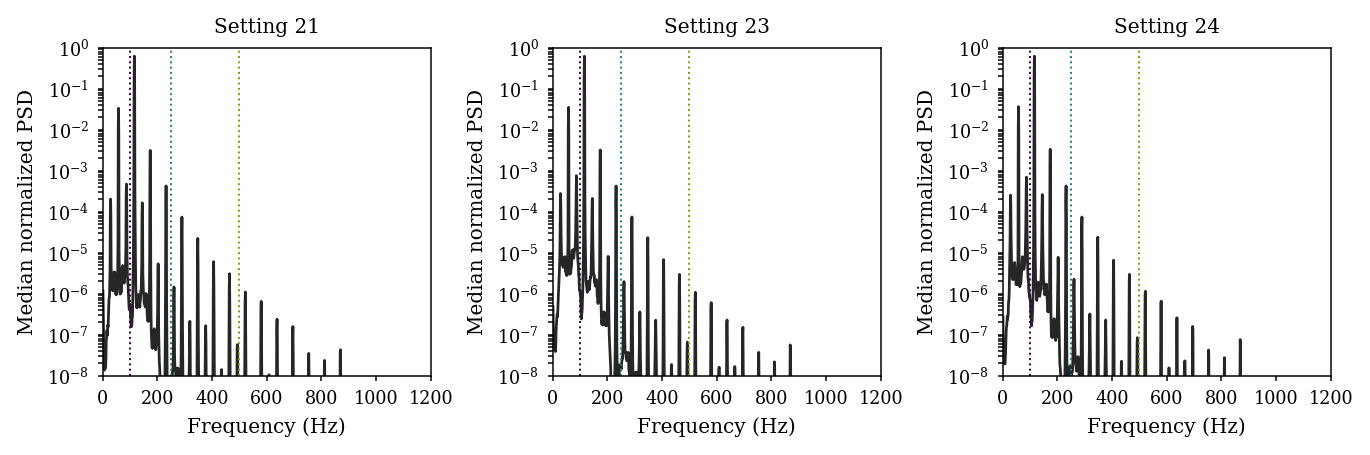

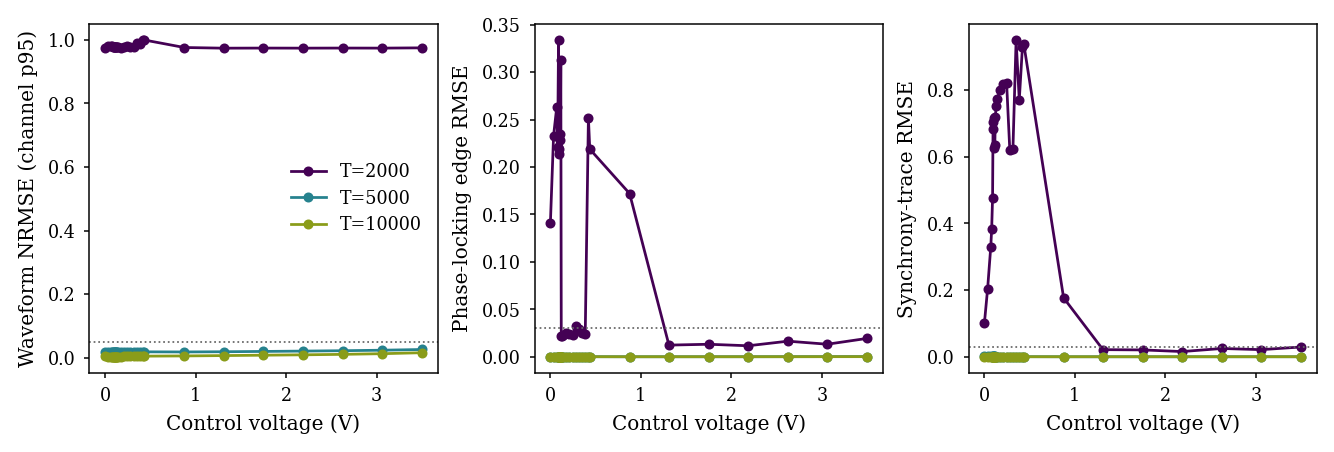

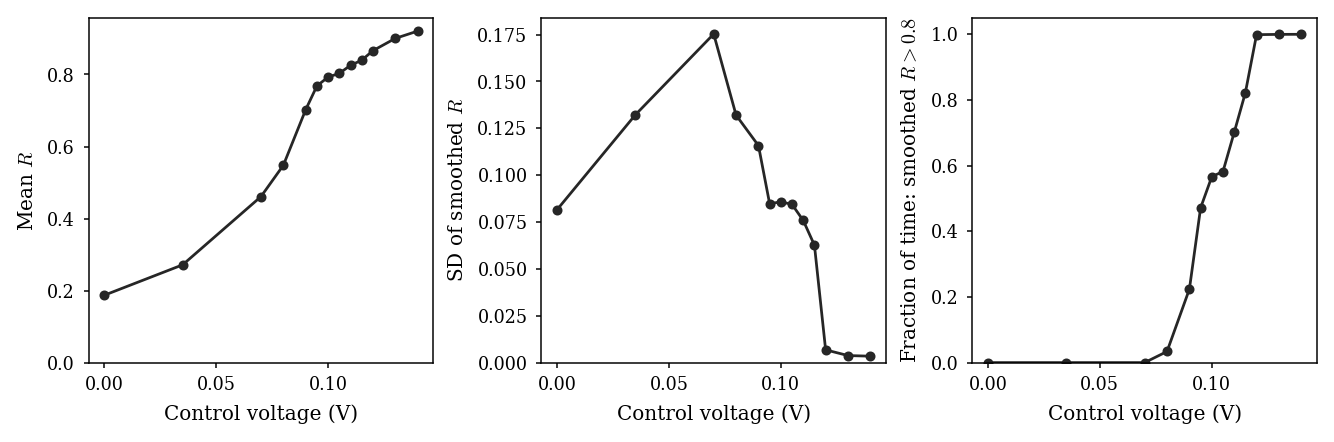

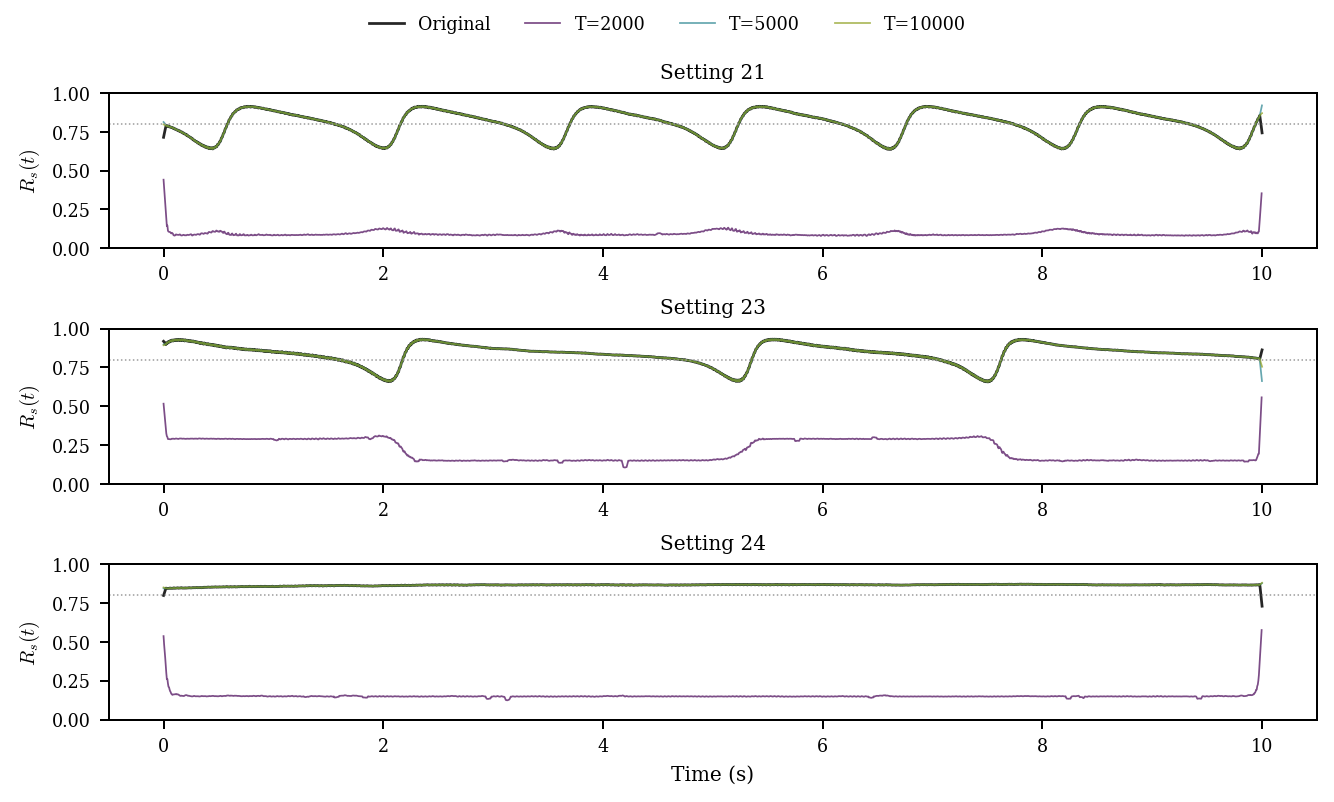

In [2]:
if (SCOPE/'sampling-decision.json').exists():
    decision = json.loads((SCOPE/'sampling-decision.json').read_text())
    print('Smallest candidate passing numerical checks:', decision['selected_T'])
    audit = pd.read_csv(SCOPE/'sampling-audit.csv')
    display(audit.groupby('T')[['fs','reconstruction_nrmse_p95','plv_rmse','envelope_rmse','synchrony_trace_rmse','high_fraction_error','passes']].agg({'fs':'first','reconstruction_nrmse_p95':'max','plv_rmse':'max','envelope_rmse':'max','synchrony_trace_rmse':'max','high_fraction_error':'max','passes':'all'}))
    figures = sampling_figures(SCOPE, trace_steps=[21, 23, 24], focus_max_step=28)
    show(figures, ['spectra','sampling-fidelity','coordination-profile','synchrony-traces'])
else:
    print('Waveform acquisition pending; T has not been selected.')

MTS snapshots use the existing `icefire` format: robust scaling per channel over the full record, then the same 1.0–1.2 s window in every panel. Colour limits are shared; channel order is unchanged. These display windows do not shorten the extracted observations.

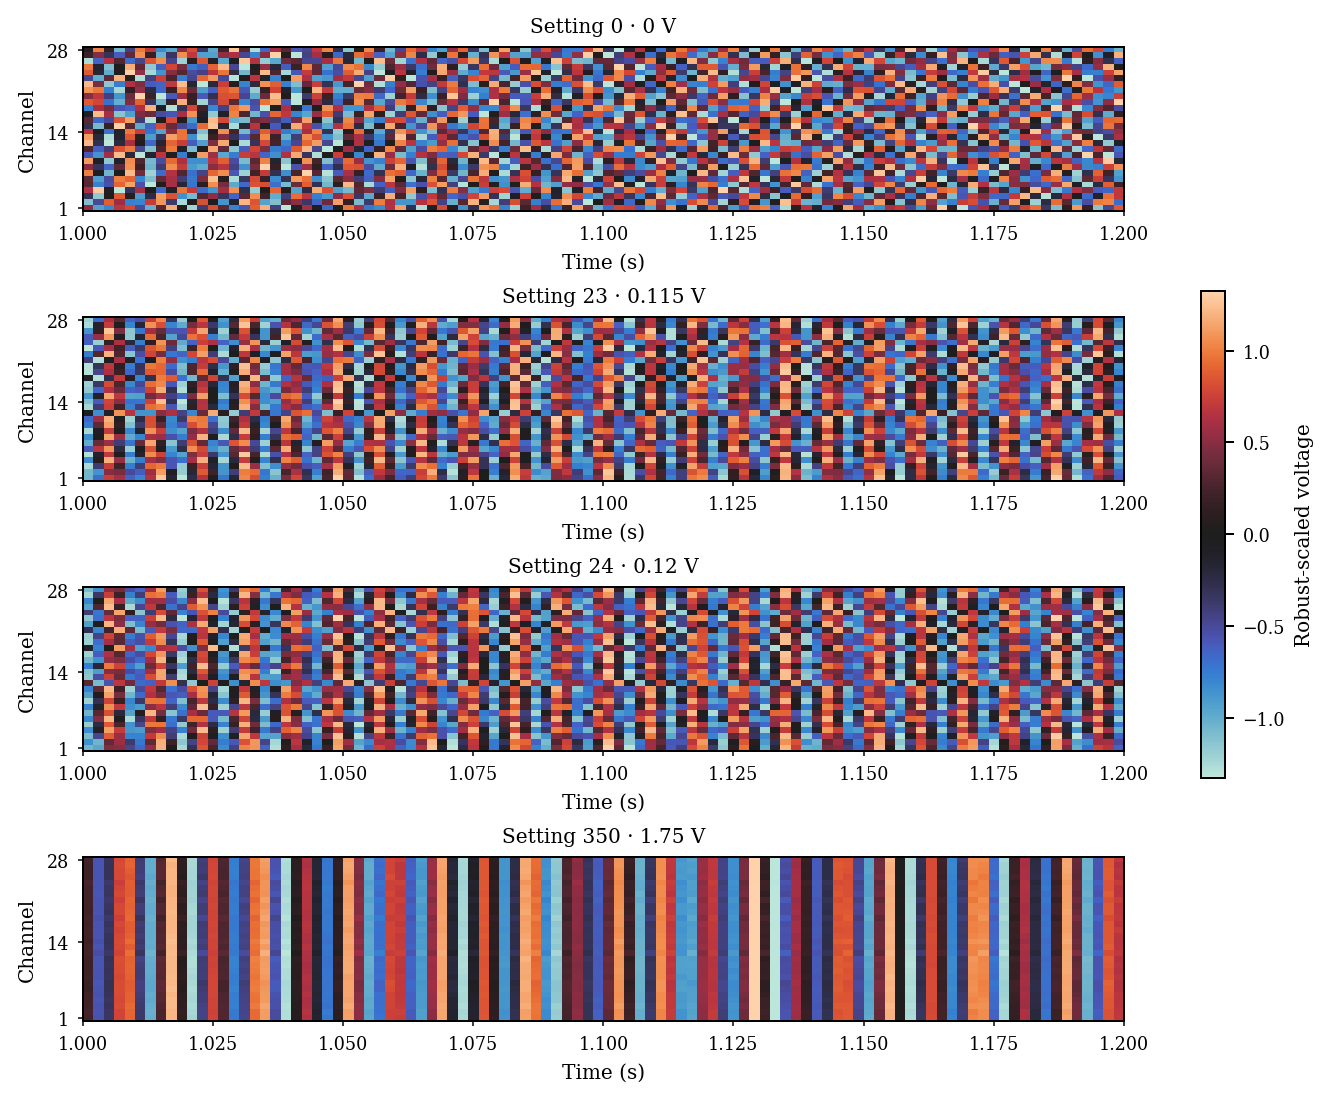

,fs,passing_records,waveform_error,envelope_error,plv_error
T,,,,,
2500,250.0,0,0.419264,0.066436,0.031170
3125,312.5,0,0.088067,0.086323,0.014135
4000,400.0,27,0.038631,0.096186,0.002359
5000,500.0,29,0.025530,0.027342,0.000230


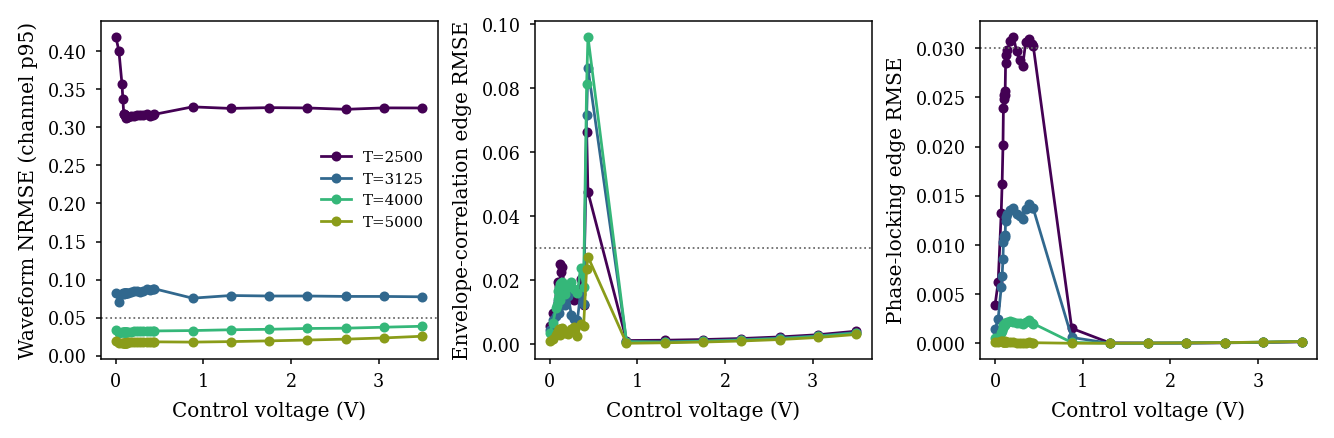

In [3]:
bank = RUN/'sweep29'
if (bank/'observations.npz').exists():
    show(mts_figures(bank), ['mts-heatmaps'])
finer = RUN/'scope-er-intermediate'
if (finer/'sampling-audit.csv').exists():
    finer_audit = pd.read_csv(finer/'sampling-audit.csv')
    display(finer_audit.groupby('T').agg(fs=('fs','first'), passing_records=('passes','sum'), waveform_error=('reconstruction_nrmse_p95','max'), envelope_error=('envelope_rmse','max'), plv_error=('plv_rmse','max')))
    show(intermediate_figures(finer), ['intermediate-fidelity'])

## Dependence geometry

29/29 records validated (M=28, T=5,000; original pyspi r7). Centred PCA uses 27,694 complete, variable features, fitted on 15 alternating development settings; 14 held settings assess interpolation within this sweep. No imputation. PC1 explains **42.7%**, PC2 **23.9%**. The largest adjacent PC1 jump is 23→24, coinciding with the independently scoped reduction in synchrony fluctuations. Settings are not independent experimental replicates.


Validation: 29 records; 289 SPIs each; finite edge coverage 95.49–98.62%; failures remain explicit.
PC1 leave-setting loading cosine range: [0.98 1.  ]
Refit excluding 1431 correlation–correlation features: PC1 score r=0.9978


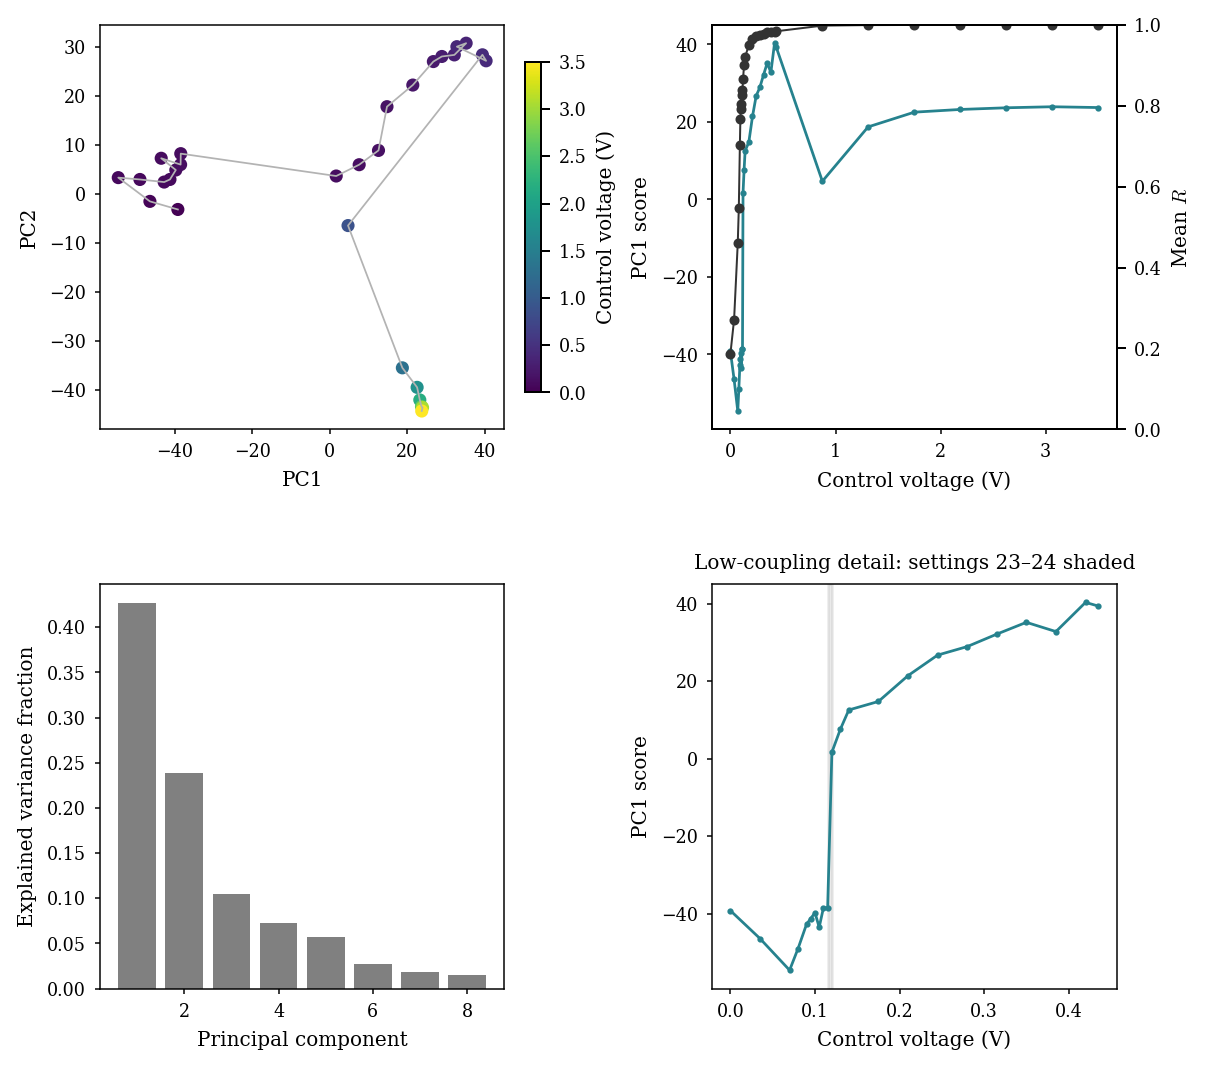

In [ ]:
ANALYSIS = RUN/MODEL_NAME/'analysis'
report = json.loads((ANALYSIS/'summary.json').read_text())
print('Validation: 29 records; 289 SPIs each; finite edge coverage 95.49–98.62%; failures remain explicit.')
print('PC1 leave-setting loading cosine range:', np.round([min(report['leave_setting_loading_cosines']), max(report['leave_setting_loading_cosines'])], 3))
sensitivity = report['correlation_exclusion_sensitivity']
print(f"Refit excluding {sensitivity['excluded_features']} correlation–correlation features: PC1 score r={sensitivity['score_correlation']:.4f}")
figures = result_figures(ANALYSIS, SCOPE)
show(figures, ['geometry'])


## Features and channel-pair explanations

19/20 largest PC1 weights pair correlation variants; rank 1 is Pearson at 2 ms × Kendall at 20 ms (w=+0.02325). These are lag-dependent edge agreements, not inferred physical delays. Removing all 1,431 correlation–correlation features and refitting preserves the trajectory (score r=.9978). The filtered gallery retains original ranks and does not refit.

Across **23→24**, stochastic interaction × IDS changes **+.534→−.905**; distance correlation × stochastic interaction changes **+.556→−.881**. Stochastic interaction compares separate versus joint one-step conditional entropies (here 2 ms); IDS measures instantaneous dependence through transformed-variable correlations. Thus, the edges strongest under instantaneous dependence switch from positive to negative association with stochastic interaction. Both reversals survive deleting any one channel’s incident edges; this is an edge sensitivity check, not estimator refitting or a confidence interval.

Mean Pearson strength also rises (.669→.709), so this is not yet a strength-matched mechanistic contrast. Kernel bandwidth, temporal resolution and an independent sweep remain interpretation checks.


Follow-up [scan](hardware-pilot-scan.ipynb): the reversal is concentrated around four less-coherent channels; removing their combined incident edges leaves negative agreement before and after. The strongest reversal is kernel-specific, and PCA axis order depends on control-setting sampling. These refine the interpretation without changing the archived results. The subsequent waveform control also qualifies the phase/envelope interpretation: high broadband agreement can arise from fixed waveform harmonics, without a separate amplitude process.

,rank,spi_a,spi_b,weight
0,1,corr_pearson_tau-1,corr_kendall_tau-10,0.023251
1,2,corr_spearman_tau-1,corr_kendall_tau-10,0.023116
2,3,corr_spearman_tau-3,corr_kendall_tau-5,0.023080
3,4,corr_pearson_tau-1,corr_kendall_tau-5,-0.022957
4,5,corr_pearson_tau-1,corr_kendall_tau-4,-0.022852
5,6,corr_spearman_tau-1,corr_kendall_tau-5,-0.022787
6,7,corr_spearman_tau-1,corr_kendall_tau-4,-0.022703
7,8,corr_spearman_tau-3,corr_kendall_tau-10,-0.022660
8,9,corr_pearson_tau-1,corr_spearman_tau-5,-0.022528


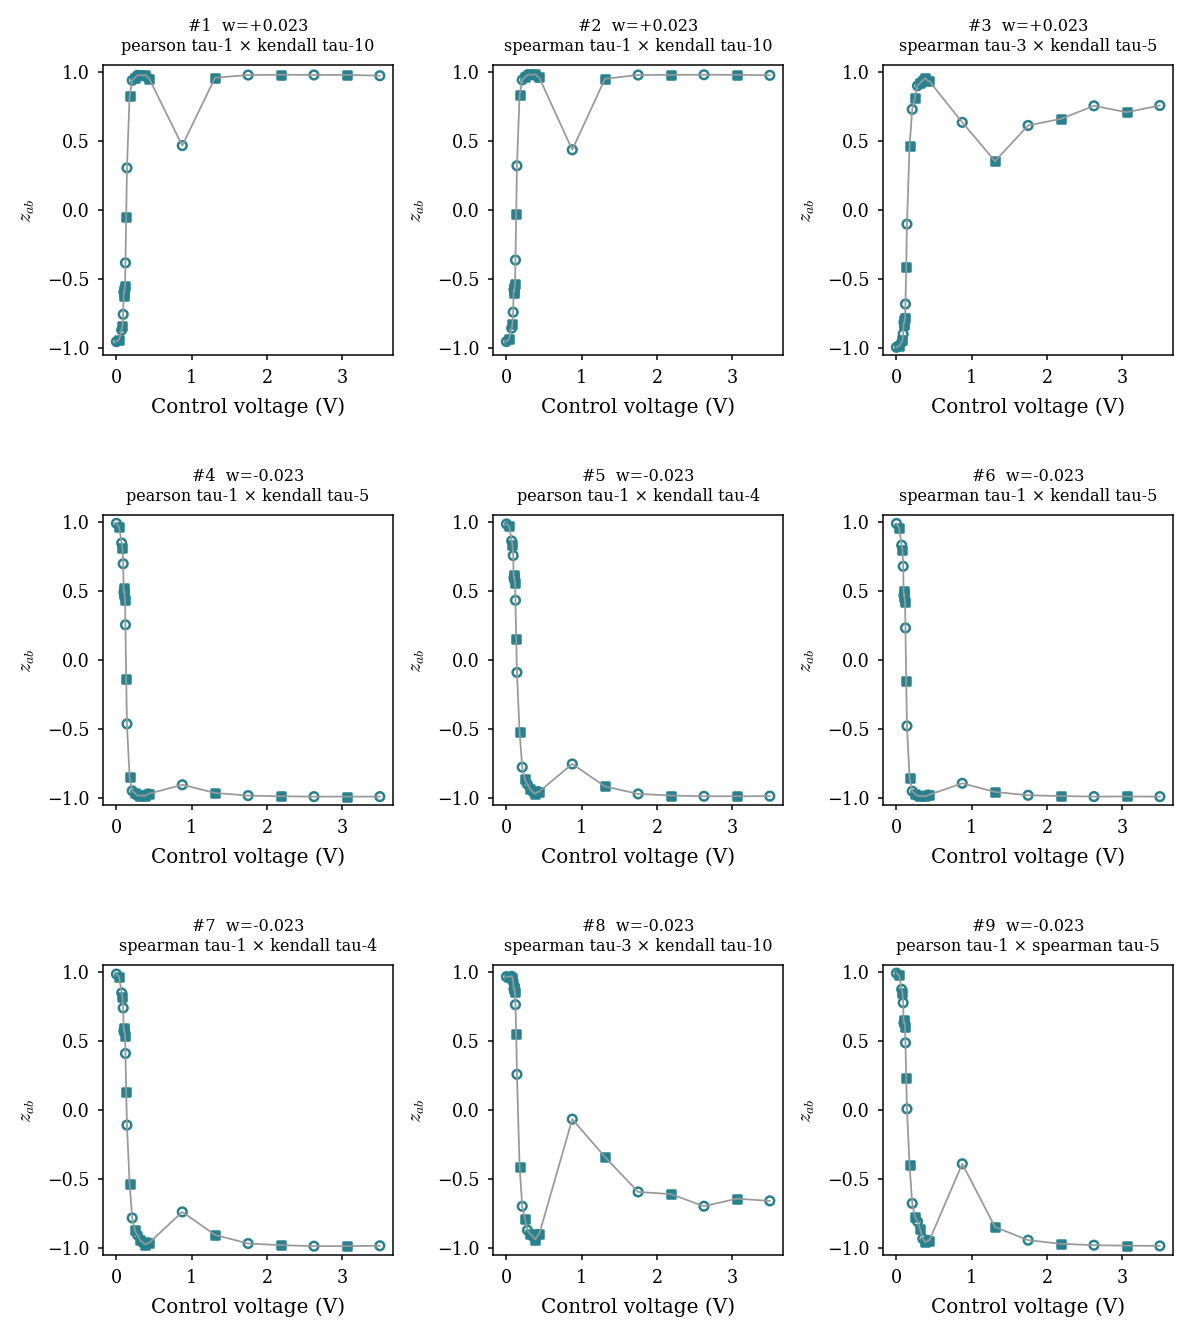

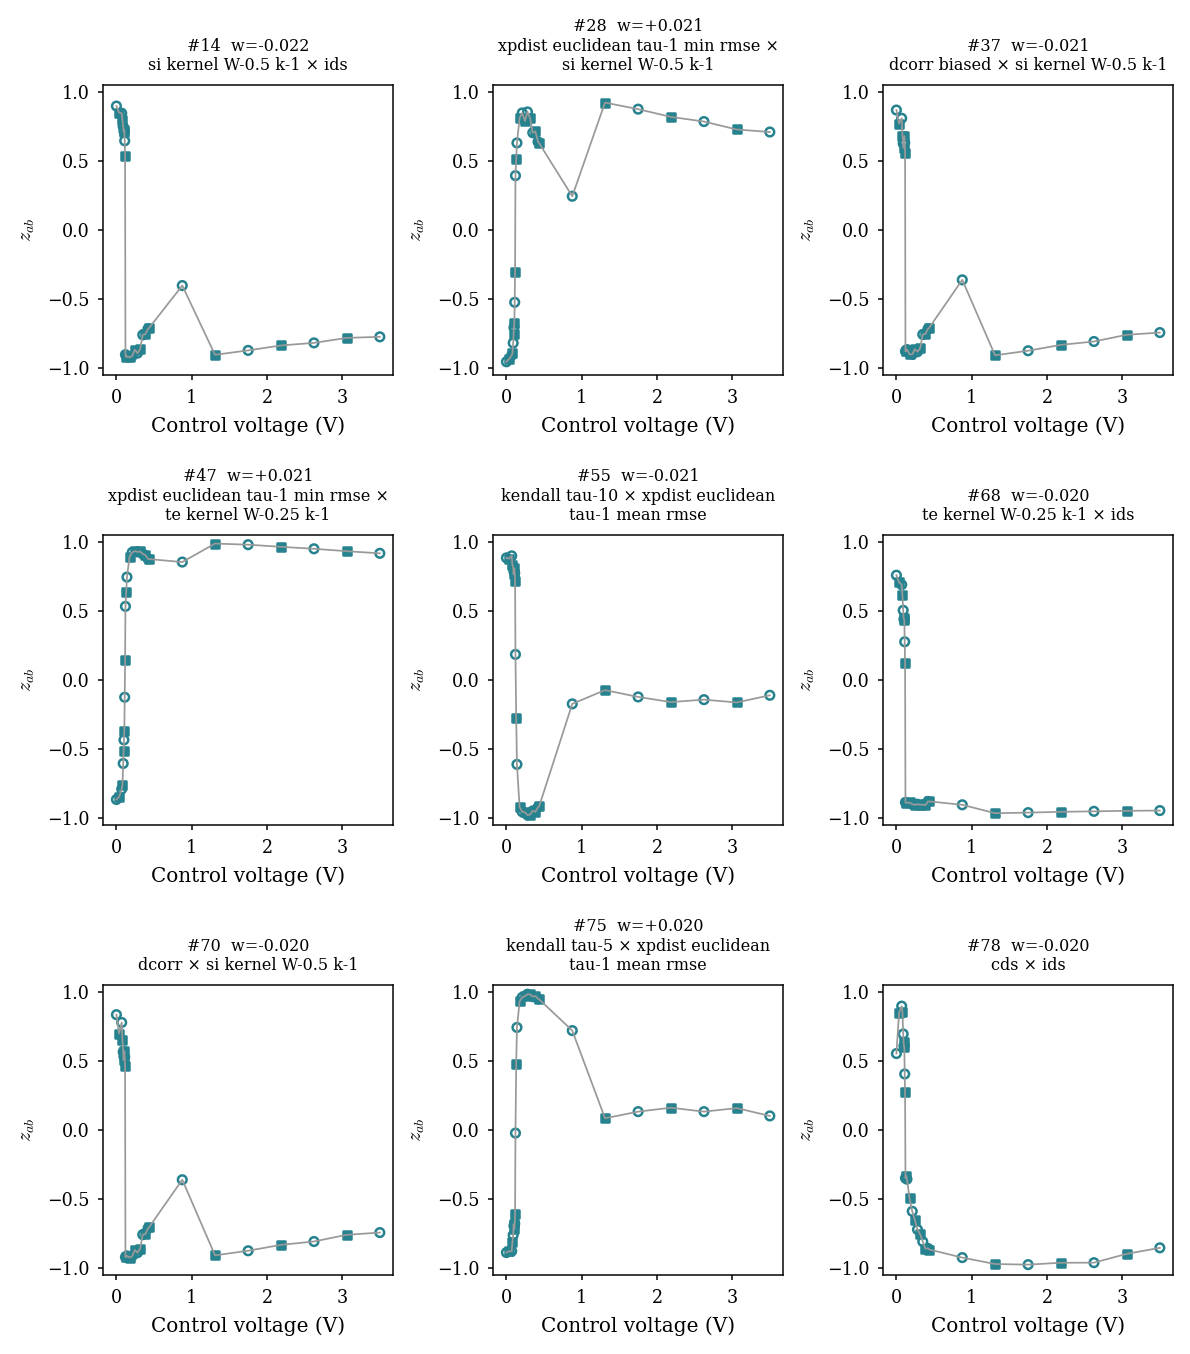

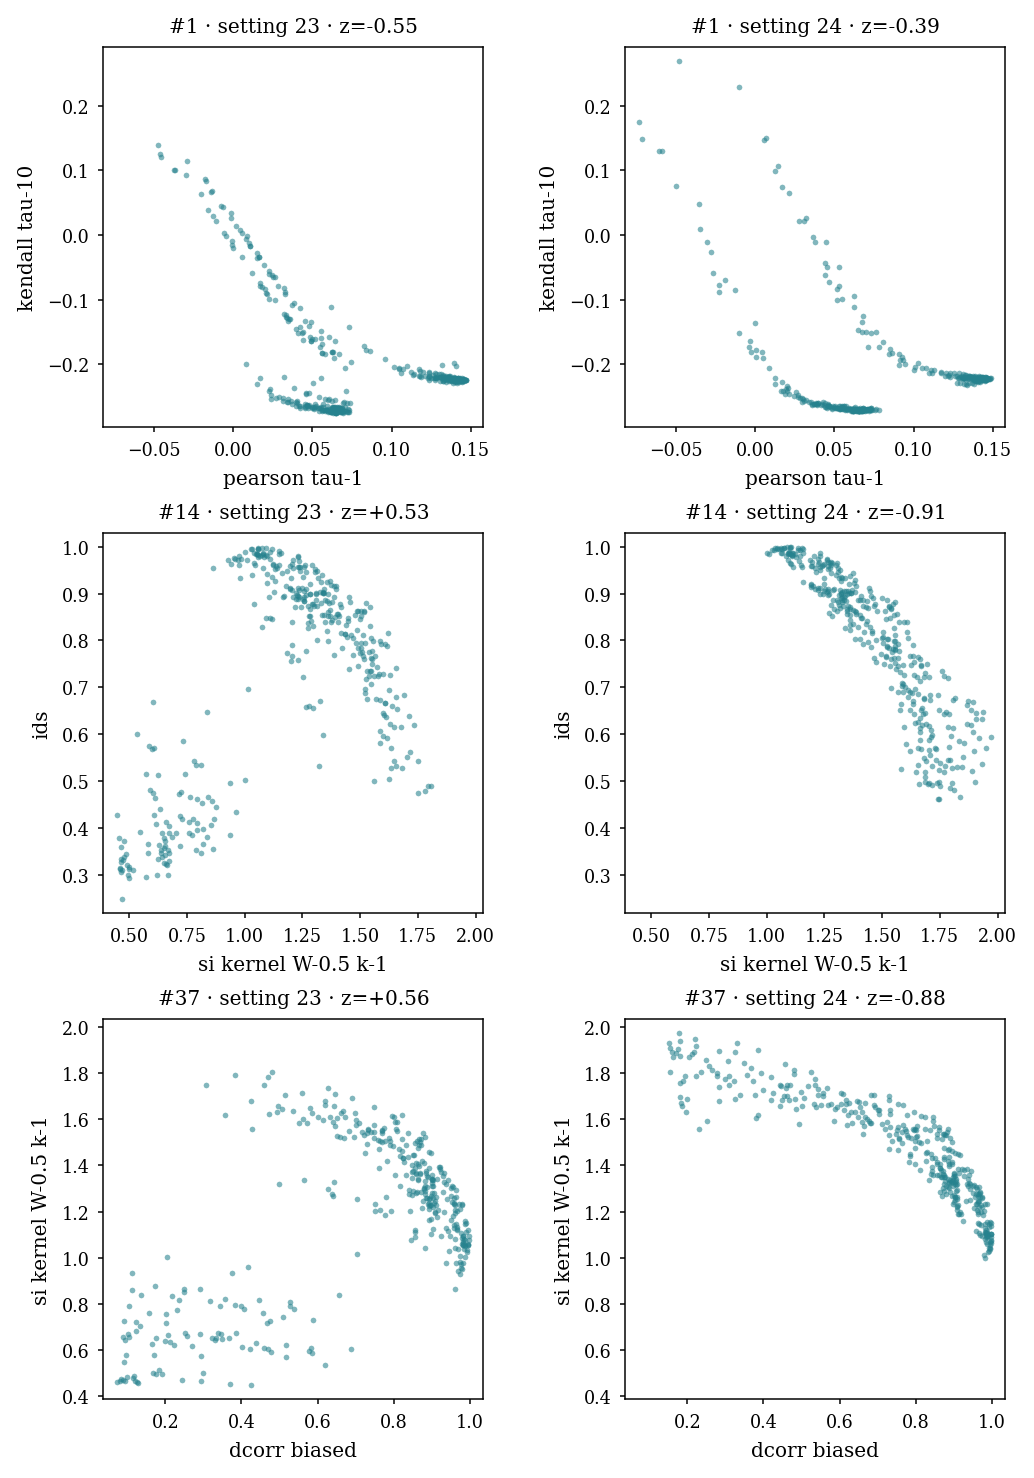

,rank,step,z,edge_spearman,channel_deletion_min,channel_deletion_max
0,1,23,-0.553,-0.280,-0.572,-0.410
1,1,24,-0.385,0.062,-0.408,-0.189
2,14,23,0.534,0.221,0.394,0.602
3,14,24,-0.905,-0.942,-0.909,-0.902
4,37,23,0.556,0.206,0.414,0.618
5,37,24,-0.881,-0.952,-0.888,-0.868


Global loading rank differs from contribution to a particular step: w × Δz.


,rank,spi_a,spi_b,pc1_contribution_23_24
0,14,si_kernel_W-0.5_k-1,ids,0.031838
1,37,dcorr_biased,si_kernel_W-0.5_k-1,0.030424
2,169,cov_GraphicalLassoCV,si_kernel_W-0.5_k-1,0.028147
3,70,dcorr,si_kernel_W-0.5_k-1,0.028135
4,97,corr_pearson_tau-20-sq,si_kernel_W-0.5_k-1,0.027790


In [ ]:
rankings = pd.read_csv(ANALYSIS/'feature-rankings.csv')
display(rankings[['rank','spi_a','spi_b','weight']].head(9))
show(figures, ['features-top','features-filtered','edge-contrast-23-24'])
contrasts = pd.read_csv(ANALYSIS/'contrast-edges.csv')
display(contrasts[['rank','step','z','edge_spearman','channel_deletion_min','channel_deletion_max']].round(3))
print('Global loading rank differs from contribution to a particular step: w × Δz.')
display(pd.read_csv(ANALYSIS/'contrast-contributions.csv')[['rank','spi_a','spi_b','pc1_contribution_23_24']].head(5))
